# 10 Regression Algorithms — Easy Student Version
**23CSE301 Machine Learning Capstone | Healthcare Cost Prediction and Patient Risk Intelligence Platform**  
This is a classroom-friendly version: **load → inspect → engineer features → split → train each model → test → plot → compare → cross-validate → tune → save**. Every model is trained on the same training data and evaluated on the same test data. **SAMPLE_ROWS = 5000** speeds up the demo; change to None for full training (may be very slow). Charts and metrics are real notebook outputs; explain them in your own words. Generated-code scaffolding must be credited in the README.

**Our answer:** How much could annual medical cost be?  
Metrics: R² (higher), RMSE and MAE (lower).

## 1. Load, audit and inspect the dataset  
**Explain in the viva:** The model must never learn from its test data. We keep a separate held-out test set.

In [1]:
# Step 1: Import simple Python and machine-learning libraries
import os
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

SEED = 42
SAMPLE_ROWS = 5000  # Easy classroom demo. Change to None for all 100,000 rows (much slower).
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Step 2: Find our CSV (works from the project folder OR the notebooks folder)
file_path = "data/medical_insurance.csv"
project_folder = "."
if not os.path.exists(file_path):
    file_path = "../data/medical_insurance.csv"
    project_folder = ".."

# Step 3: Create folders to store the answers
os.makedirs(os.path.join(project_folder, "results"), exist_ok=True)
os.makedirs(os.path.join(project_folder, "models"), exist_ok=True)
RESULTS = Path(project_folder) / "results"
MODELS = Path(project_folder) / "models"

# Step 4: Read and inspect the dataset
df = pd.read_csv(file_path)
print("Dataset shape:", df.shape)
print("Missing cells:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.head())

Dataset shape: (100000, 54)
Missing cells: 30083
Duplicate rows: 0


,person_id,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,bmi,smoker,alcohol_freq,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,diastolic_bp,ldl,hba1c,plan_type,network_tier,deductible,copay,policy_term_years,policy_changes_last_2yrs,provider_quality,risk_score,annual_medical_cost,annual_premium,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,hypertension,diabetes,asthma,copd,cardiovascular_disease,cancer_history,kidney_disease,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,75722,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,1,27.4,Never,NaN,2,0,0,4,121.0,76.0,123.8,5.28,PPO,Bronze,1000,20,4,0,3.73,0.5714,6938.06,876.05,73.00,1,4672.59,4672.59,1,0,0,0,0,0,0,0,0,1,0,1,0,2,0,1,0,0
1,80185,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,1,26.6,Never,Weekly,2,0,0,3,131.0,79.0,97.3,4.82,POS,Gold,1000,10,1,0,3.10,1.0000,1632.61,445.10,37.09,4,297.27,1189.08,2,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0
2,19865,68,Male,North,Rural,40700.0,HS,Married,Retired,5,3,31.5,Never,NaN,1,0,0,4,160.0,84.0,129.5,5.51,HMO,Platinum,500,20,10,0,3.90,1.0000,7661.01,1538.02,128.17,0,0.00,0.00,3,1,0,0,0,0,1,0,0,0,1,1,0,2,1,0,1,0
3,76700,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,3,31.6,Never,NaN,0,0,0,1,104.0,68.0,160.3,8.50,HMO,Silver,500,20,5,0,3.89,0.2857,5130.27,820.63,68.39,0,0.00,0.00,1,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0
4,92992,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,0,30.5,Never,Daily,3,0,0,2,136.0,83.0,171.0,5.20,POS,Platinum,500,10,7,0,3.90,0.8681,1700.73,500.93,41.74,1,1002.24,1002.24,2,1,0,0,0,0,0,0,0,1,0,2,0,1,1,0,1,0


,annual_medical_cost,age,bmi,income
count,100000.00,100000.00,100000.00,100000.00
mean,3009.45,47.52,26.99,49873.90
std,3127.46,15.99,4.99,46800.21
min,55.55,0.00,12.00,1100.00
25%,1175.12,37.00,23.60,21100.00
50%,2082.57,48.00,27.00,36200.00
75%,3707.96,58.00,30.40,62200.00
max,65724.90,100.00,50.40,1061800.00


Missing by column (nonzero):


,Missing
alcohol_freq,30083


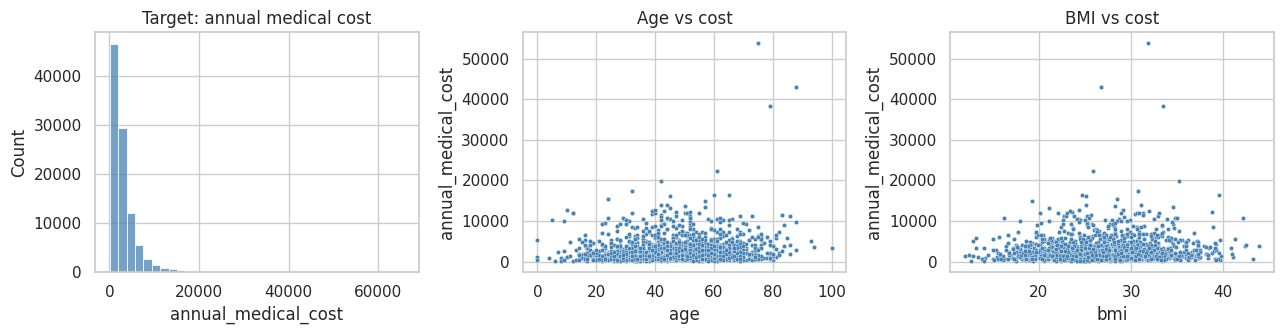

In [2]:
display(df[['annual_medical_cost','age','bmi','income']].describe().round(2))
print('Missing by column (nonzero):')
display(df.isna().sum()[lambda s:s>0].to_frame('Missing'))
fig,ax=plt.subplots(1,3,figsize=(13,3.5))
sns.histplot(df['annual_medical_cost'],bins=35,ax=ax[0],color='steelblue');ax[0].set_title('Target: annual medical cost')
sns.scatterplot(data=df.sample(1500,random_state=SEED),x='age',y='annual_medical_cost',s=10,ax=ax[1],color='steelblue');ax[1].set_title('Age vs cost')
sns.scatterplot(data=df.sample(1500,random_state=SEED),x='bmi',y='annual_medical_cost',s=10,ax=ax[2],color='steelblue');ax[2].set_title('BMI vs cost')
plt.tight_layout();plt.show()
# IMPORTANT: Write your OWN observations here after looking at the plots.


### EDA supplement — feature distributions, heatmap, outliers and written observations
The Review 1 rubric also asks for **a distribution plot for every feature**, a correlation heatmap, target distribution and outlier checks. To avoid 50 full-screen charts, we show a **page of 12 small distributions at a time**, using 2,500 sampled records for faster visuals.

**Write your own observations** after running: which variables are skewed, which have unusual outliers, and which correlate with `annual_medical_cost`?

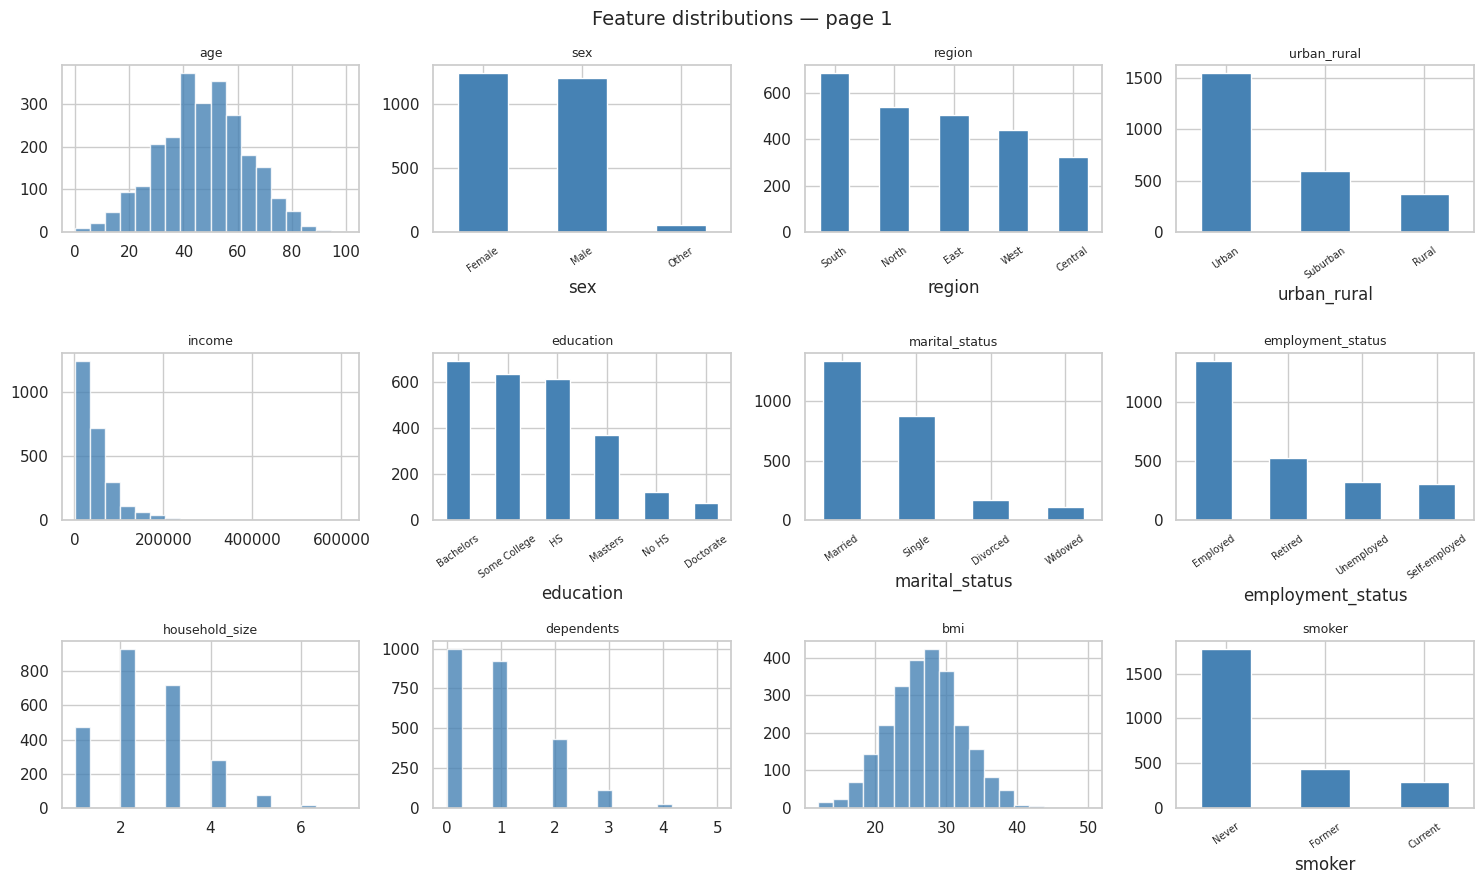

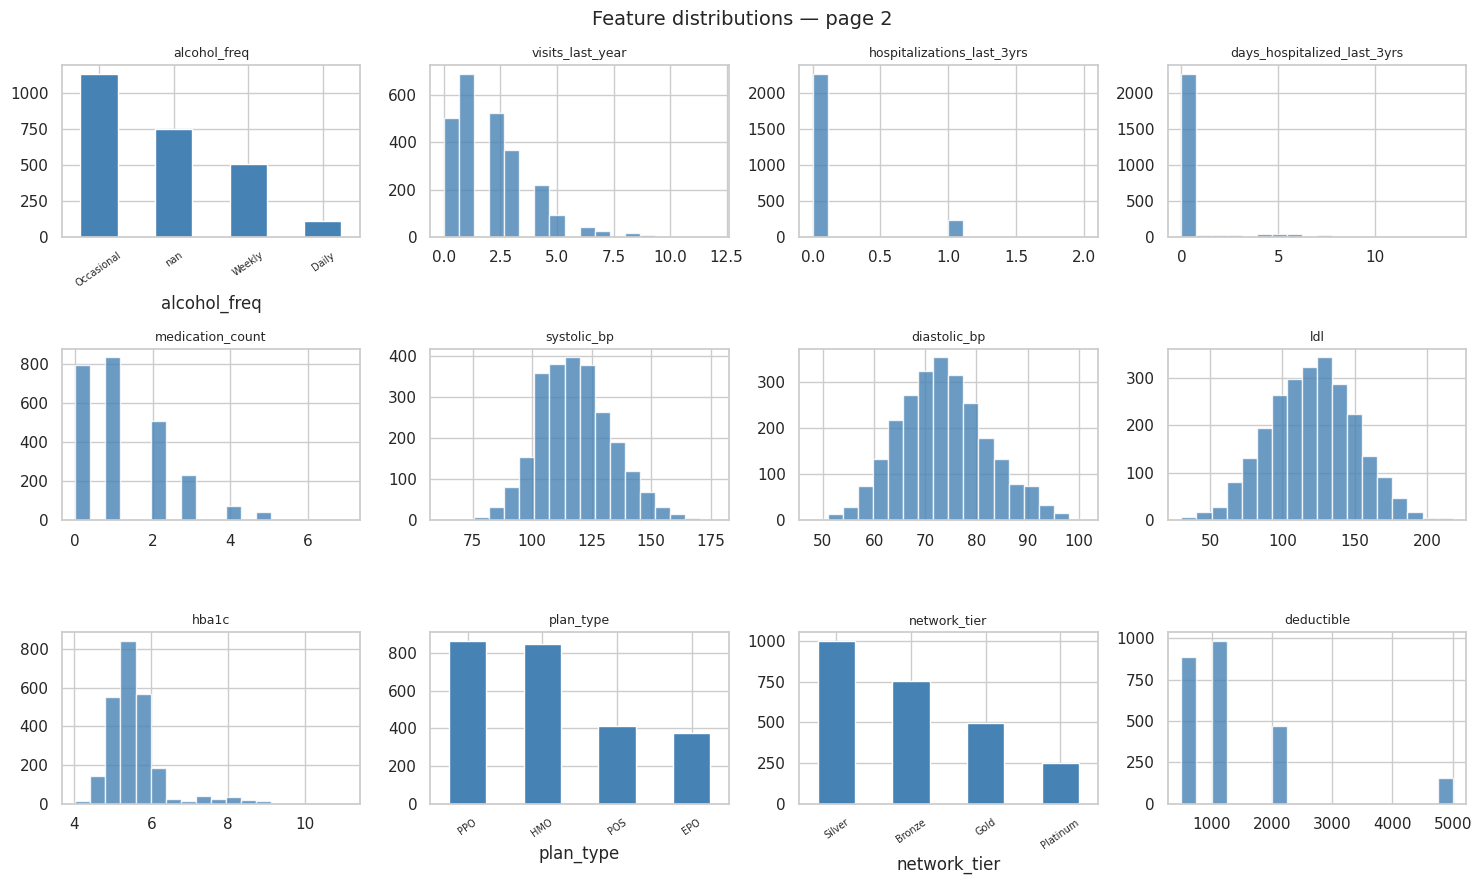

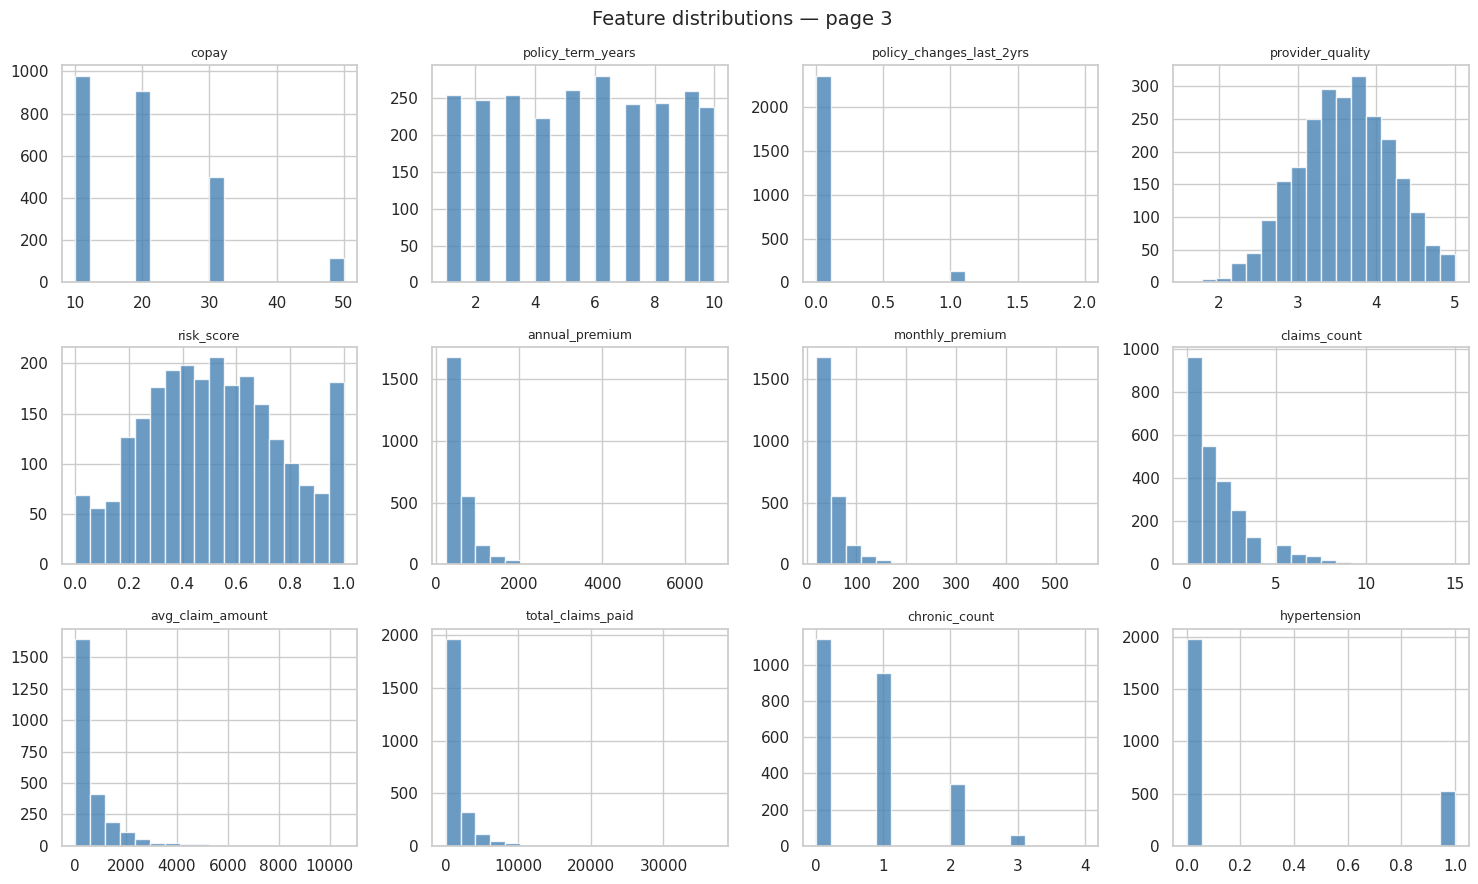

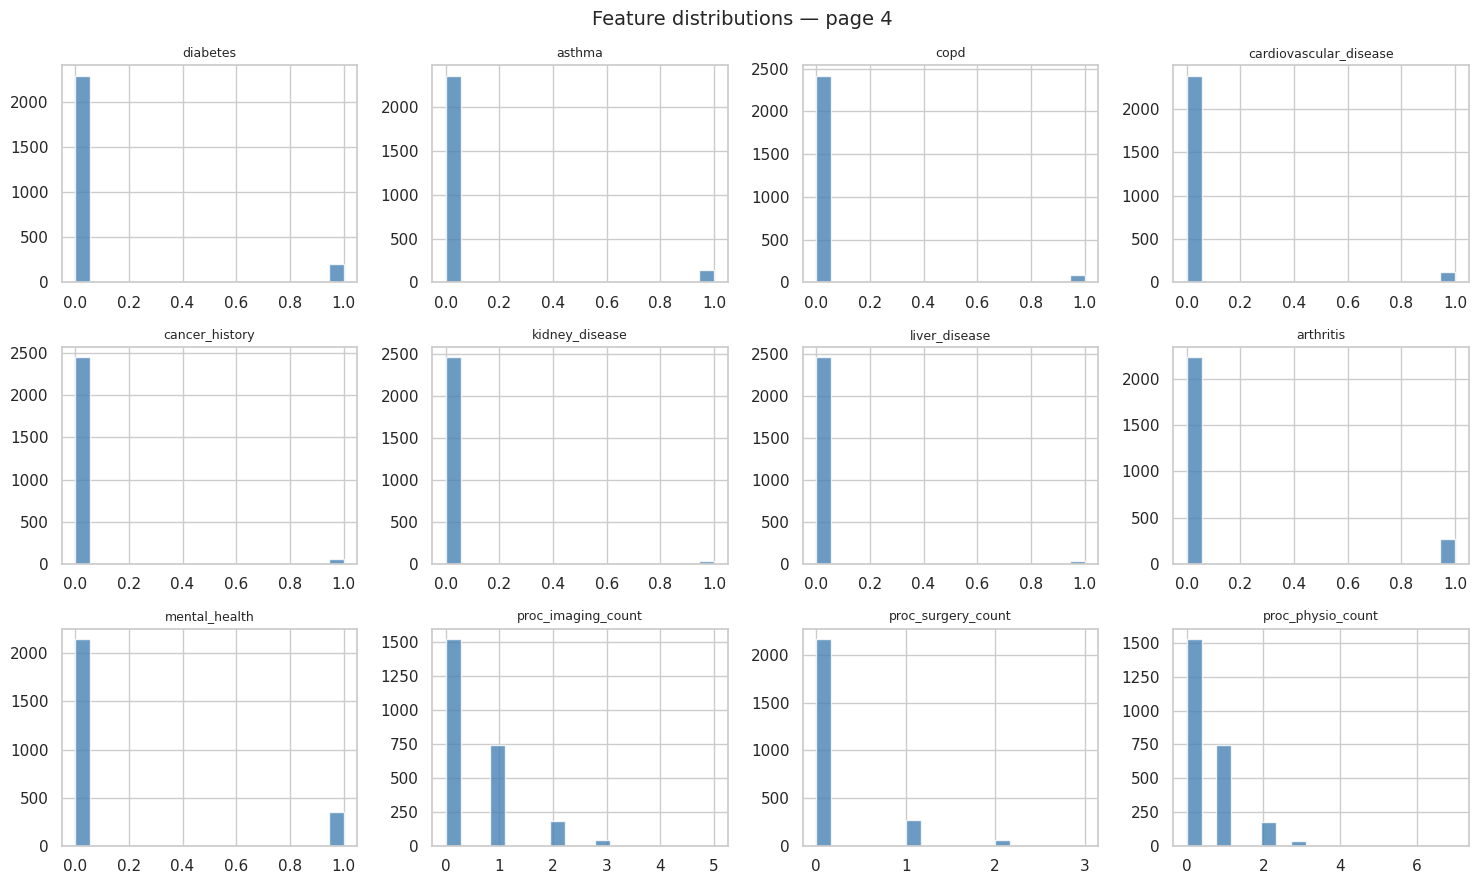

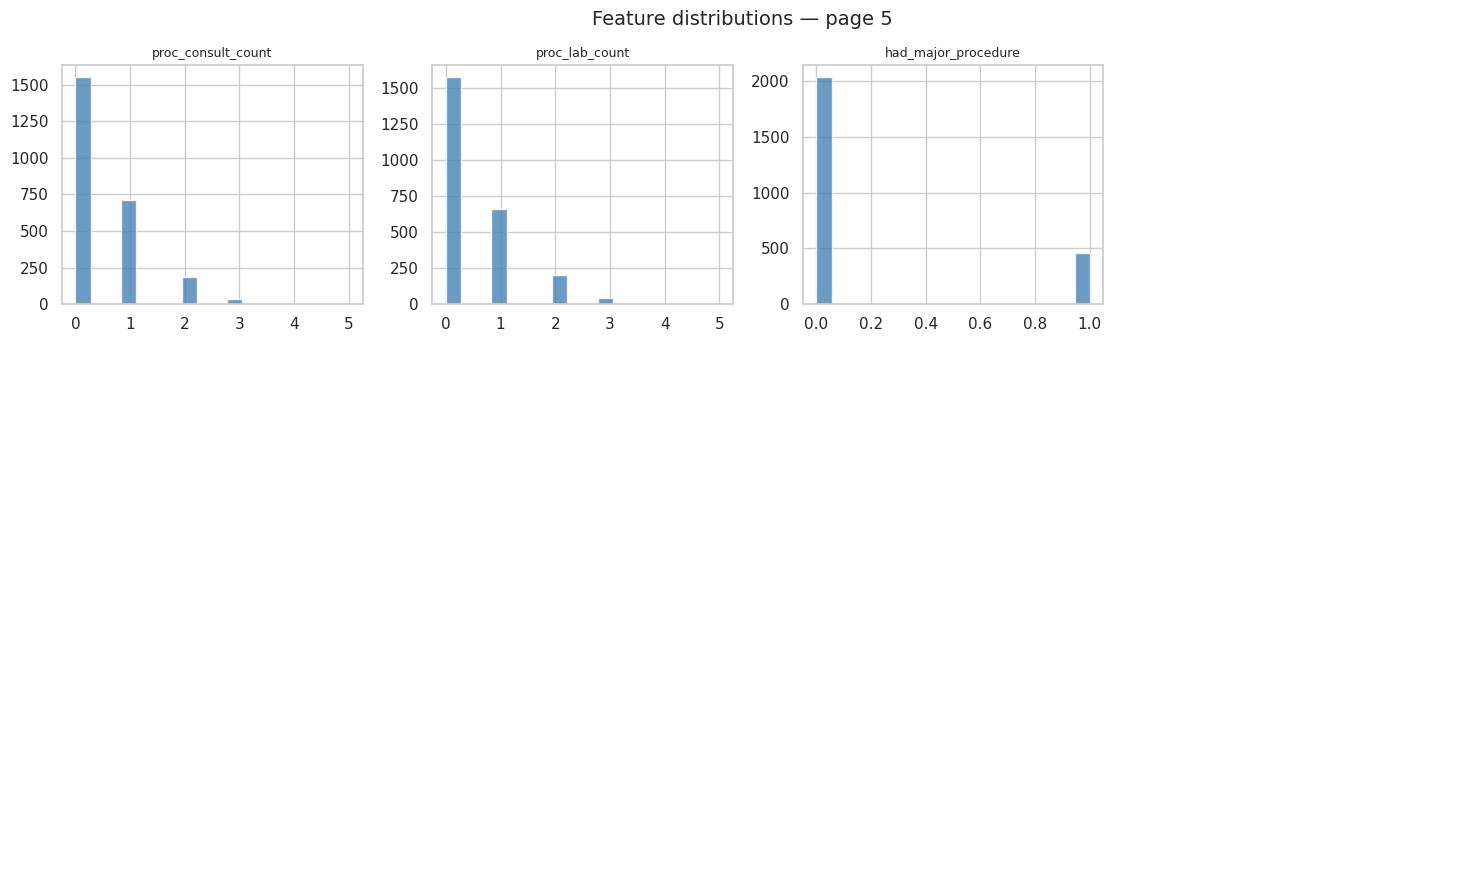

In [3]:
# Plot a distribution for EVERY raw feature except the ID and target labels.
plot_df=df.sample(n=min(2500,len(df)),random_state=SEED)
plot_cols=[col for col in df.columns if col not in ['person_id','annual_medical_cost','is_high_risk']]
for start in range(0,len(plot_cols),12):
    cols=plot_cols[start:start+12]
    fig,axes=plt.subplots(3,4,figsize=(15,9))
    for ax,col in zip(axes.ravel(),cols):
        v=plot_df[col]
        if pd.api.types.is_numeric_dtype(v):
            ax.hist(v.dropna(),bins=18,color='steelblue',alpha=.8)
        else:
            v.value_counts(dropna=False).head(7).plot.bar(ax=ax,color='steelblue')
            ax.tick_params(axis='x',labelrotation=35,labelsize=7)
        ax.set_title(col,fontsize=9)
    for ax in axes.ravel()[len(cols):]:ax.axis('off')
    fig.suptitle(f'Feature distributions — page {start//12+1}',fontsize=14)
    plt.tight_layout();plt.show()


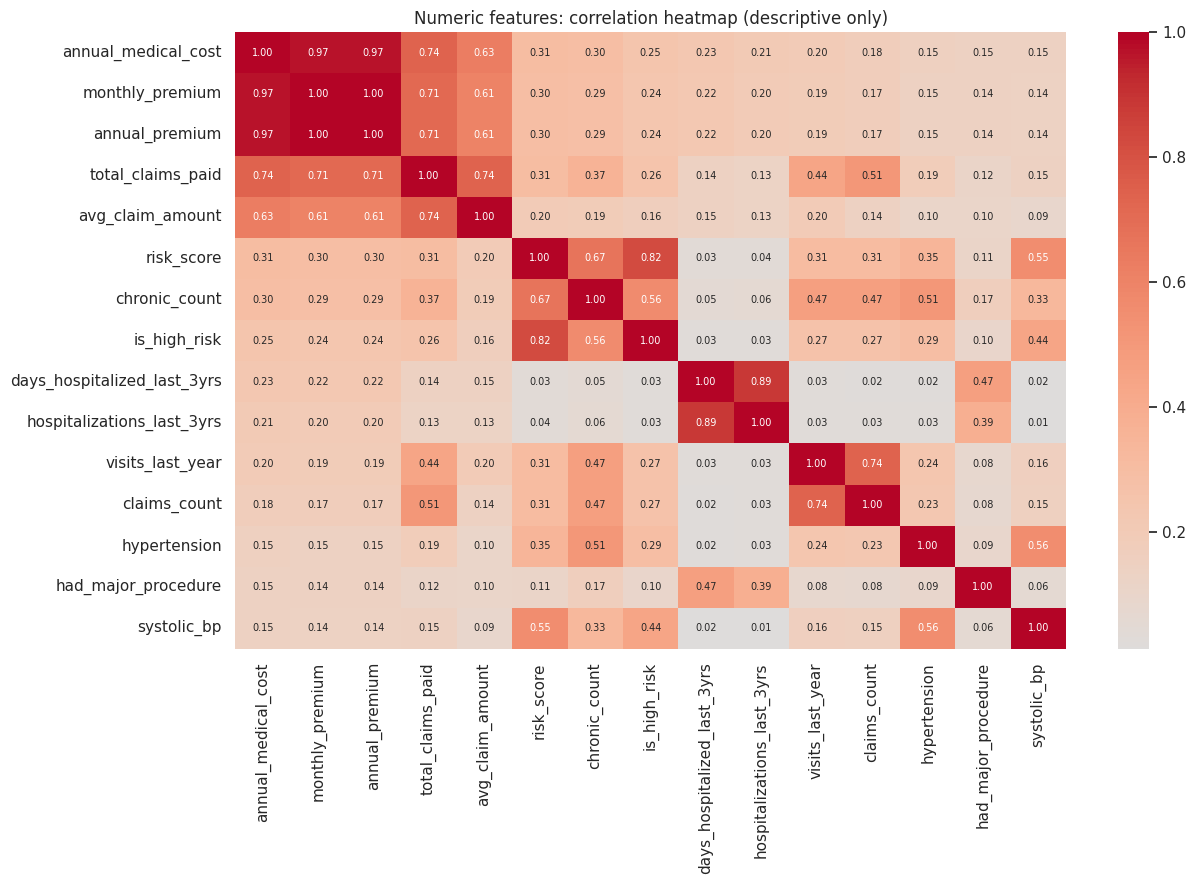

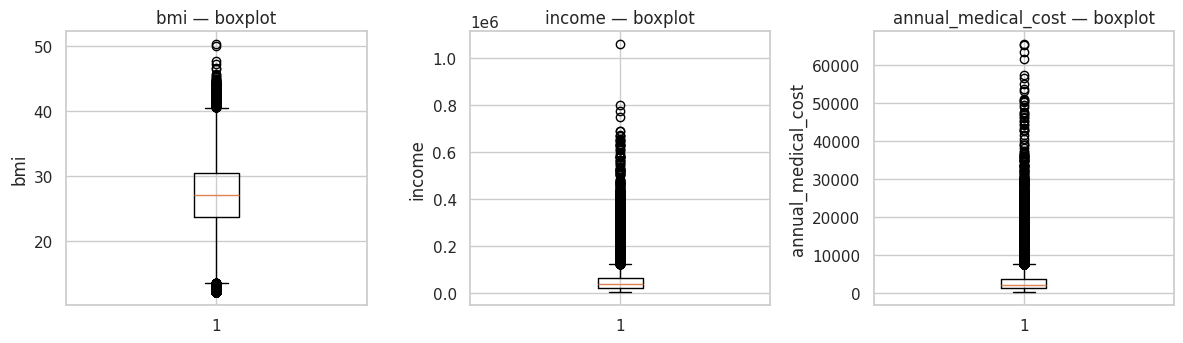

NOTE: Correlation or an apparent outlier does not by itself justify deleting data.


In [4]:
# Correlation heatmap: show target + 14 strongest-correlated numeric variables.
numeric_df=df.select_dtypes(include=np.number)
top_corr=(numeric_df.corr()['annual_medical_cost'].drop('annual_medical_cost').abs().sort_values(ascending=False).index[:14]).tolist()
chosen=['annual_medical_cost']+top_corr
plt.figure(figsize=(13,9))
sns.heatmap(numeric_df[chosen].corr(),cmap='coolwarm',center=0,annot=True,fmt='.2f',annot_kws={'fontsize':7})
plt.title('Numeric features: correlation heatmap (descriptive only)')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(12,3.6))
for ax,col in zip(axes,['bmi','income','annual_medical_cost']):
    ax.boxplot(df[col].dropna(),vert=True);ax.set_title(col+' — boxplot');ax.set_ylabel(col)
plt.tight_layout();plt.show()
print('NOTE: Correlation or an apparent outlier does not by itself justify deleting data.')


## 2. Feature engineering and split  
**Why?** Features summarise BMI, age, lifestyle and healthcare use. The same rows and held-out test set are used for all 10 models.

In [5]:
# Step 1: Seven engineered features used throughout our project.
# Each feature is a simple formula using already-available columns.
def feature_engineering(data):
    d = data.copy()

    # 1. Divide BMI into understandable groups.
    d['BMI_Category'] = pd.cut(
        d['bmi'], [-np.inf, 18.5, 25, 30, np.inf],
        labels=['Underweight', 'Normal', 'Overweight', 'Obese']
    ).astype(str)

    # 2. Group patients by age.
    d['Age_Group'] = pd.cut(
        d['age'], [-np.inf, 30, 55, np.inf],
        labels=['Youth', 'Middle-aged', 'Senior']
    ).astype(str)

    # 3. Add a simple score for smoking, BMI and mental health.
    smoking_points = np.where(
        d['smoker'] == 'Current', 3,
        np.where(d['smoker'] == 'Former', 1, 0)
    )
    d['Lifestyle_Risk_Score'] = (
        smoking_points + (d['bmi'] >= 30).astype(int)
        + 0.5 * d['mental_health'].fillna(0)
    )

    # 4. Add up visits, hospital stays and procedures.
    d['Hospital_Utilization_Score'] = (
        d['visits_last_year']
        + 3 * d['hospitalizations_last_3yrs']
        + 0.5 * d['days_hospitalized_last_3yrs']
        + 2 * d['proc_surgery_count']
        + d['proc_imaging_count']
    )

    # 5. Compare premium with deductible + premium.
    d['Insurance_Coverage_Ratio'] = (
        d['annual_premium'] /
        (d['deductible'] + d['annual_premium'] + 0.00001)
    ).clip(0, 1)

    # 6. Count listed chronic illnesses.
    chronic = ['hypertension','diabetes','asthma','copd',
               'cardiovascular_disease','cancer_history',
               'kidney_disease','liver_disease','arthritis']
    d['Total_Chronic_Diseases'] = d[chronic].sum(axis=1)

    # 7. Summarise medical severity and hospital usage.
    d['Claim_Severity_Index'] = (
        0.05 * d['age'] + 0.1 * d['bmi']
        + 1.5 * d['Total_Chronic_Diseases']
        + 0.5 * d['Hospital_Utilization_Score']
        + 1.5 * d['had_major_procedure']
    )
    return d

# Remove direct outcomes, IDs and obvious post-outcome/derived claims fields.
# Our team must still audit whether other columns were available at prediction time.
DROP=['person_id','annual_medical_cost','is_high_risk','risk_score','total_claims_paid','avg_claim_amount']
D=feature_engineering(df.drop_duplicates()).copy()
CAT=[c for c in D.select_dtypes(include=['object','category']).columns if c not in DROP]
FEATURES=[c for c in D.columns if c not in DROP]
NUM=[c for c in FEATURES if c not in CAT]

# The same preprocessing is fitted on TRAINING data only.
# Numbers: fill missing values with median, then standardize.
# Categories: fill missing values, then one-hot encode.
def make_prep():
    return ColumnTransformer([
        ('numbers',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),NUM),
        ('categories',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),CAT)
    ],sparse_threshold=0)

print('Predictors:',len(FEATURES),'| Numeric:',len(NUM),'| Categorical:',len(CAT))
print('Leakage columns removed:',[x for x in DROP if x in D.columns])
assert not (set(FEATURES) & set(DROP))

# Regression-specific availability audit: premiums in this synthetic dataset
# are strongly associated with annual cost and could contain outcome information.
# Remove both premiums and the engineered ratio made from them; claims_count
# may reflect activity from the same outcome year, so exclude it too.
REG_EXTRA_DROP=['annual_premium','monthly_premium','Insurance_Coverage_Ratio','claims_count']
FEATURES=[f for f in FEATURES if f not in REG_EXTRA_DROP]
CAT=[f for f in CAT if f in FEATURES]
NUM=[f for f in NUM if f in FEATURES]
print('Extra regression leakage exclusions:',REG_EXTRA_DROP)
print('Final regression predictors:',len(FEATURES))


Predictors: 55 | Numeric: 43 | Categorical: 12
Leakage columns removed: ['person_id', 'annual_medical_cost', 'is_high_risk', 'risk_score', 'total_claims_paid', 'avg_claim_amount']
Extra regression leakage exclusions: ['annual_premium', 'monthly_premium', 'Insurance_Coverage_Ratio', 'claims_count']
Final regression predictors: 51


In [6]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
valid=D['annual_medical_cost'].notna()
X_all=D.loc[valid,FEATURES]
y_all=D.loc[valid,'annual_medical_cost']
if SAMPLE_ROWS is not None:
    # Fixed random sample speeds up the viva demo; change SAMPLE_ROWS=None for full-data training.
    sample_idx=X_all.sample(n=min(SAMPLE_ROWS,len(X_all)),random_state=SEED).index
    X_all,y_all=X_all.loc[sample_idx],y_all.loc[sample_idx]
X_train,X_test,y_train,y_test=train_test_split(X_all,y_all,test_size=.20,random_state=SEED)
print('Training:',X_train.shape,'| Testing:',X_test.shape)
print('All 10 models receive these SAME train/test rows.')


Training: (4000, 51) | Testing: (1000, 51)
All 10 models receive these SAME train/test rows.


## 3. Train the ten regressors (one cell per algorithm)  
Every training cell uses the same preprocessing rules. The **model-specific plots** compare predictions against reality and show residual errors. Better models have points closer to the diagonal and smaller residuals.

### How each regressor is tested
  We use one short **helper function**, `run_regression`, to repeat the same steps for every model: **(1)** create preprocessing pipeline; **(2)** train with `.fit`; **(3)** predict test costs using `.predict`; **(4)** compute R²/RMSE/MAE; **(5)** draw actual-vs-predicted and residual graphs. The algorithm names are below, one separate cell per model.

In [7]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

# We call this easy helper once per algorithm below.
# Steps: fit -> predict -> metrics -> two pictures.
reg_results = []
reg_models = {}

def run_regression(name, algorithm, extra_step=None):
    steps = [('prepare', make_prep())]
    if extra_step is not None:
        steps.extend(extra_step)
    steps.append(('model', algorithm))
    model = Pipeline(steps)

    # TRAIN the model.
    start = time.perf_counter()
    model.fit(X_train, y_train)

    # TEST on unseen data, and separately show training performance.
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    train_r2 = r2_score(y_train, train_prediction)
    test_r2 = r2_score(y_test, test_prediction)
    rmse = np.sqrt(mean_squared_error(y_test, test_prediction))
    mae = mean_absolute_error(y_test, test_prediction)

    # Store the scores in a table (same metrics for all ten models).
    reg_results.append({'Model': name, 'Train R2': train_r2,
                        'Test R2': test_r2, 'RMSE': rmse, 'MAE': mae})
    reg_models[name] = model
    print(name)
    print('Train R2:', round(train_r2, 3), '| Test R2:', round(test_r2, 3))
    print('RMSE:', round(rmse, 2), '| MAE:', round(mae, 2))
    print('Training seconds:', round(time.perf_counter() - start, 1))

    # Plot A: closer to the dashed line means more accurate predictions.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(y_test, test_prediction, alpha=0.35, s=12)
    lower = min(y_test.min(), test_prediction.min())
    upper = max(y_test.max(), test_prediction.max())
    axes[0].plot([lower, upper], [lower, upper], 'r--', label='Perfect prediction')
    axes[0].set_title(name + ': Actual vs Predicted')
    axes[0].set_xlabel('Actual medical cost')
    axes[0].set_ylabel('Predicted medical cost')
    axes[0].legend()

    # Plot B: residual = true value - prediction.
    residuals = y_test - test_prediction
    axes[1].scatter(test_prediction, residuals, alpha=0.35, s=12)
    axes[1].axhline(0, color='red', linestyle='--')
    axes[1].set_title(name + ': Residuals')
    axes[1].set_xlabel('Predicted medical cost')
    axes[1].set_ylabel('Actual - Predicted')
    plt.tight_layout()
    plt.show()
    return model


### 1. Linear Regression
**Linear Regression:** Draws a best-fit linear relationship. Look at how close predictions are to the diagonal.

Linear Regression
Train R2: 0.185 | Test R2: 0.181
RMSE: 2699.03 | MAE: 1712.43
Training seconds: 0.1


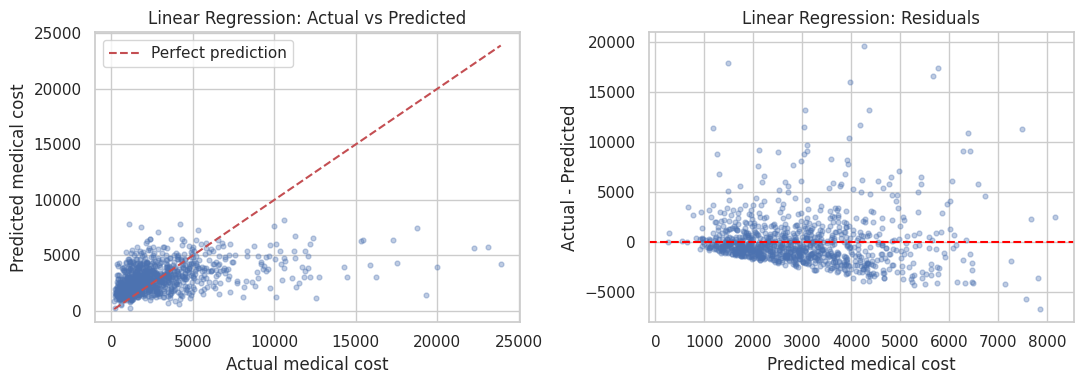

In [8]:
m_1=run_regression('Linear Regression',LinearRegression())

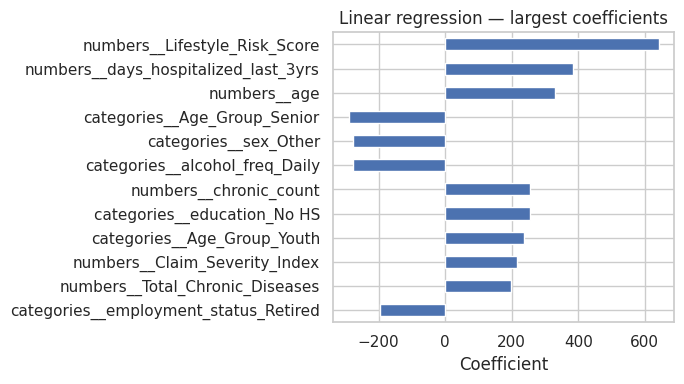

In [9]:
coefs=pd.Series(m_1.named_steps['model'].coef_,index=m_1.named_steps['prepare'].get_feature_names_out()).sort_values(key=np.abs).tail(12)
coefs.plot.barh(figsize=(7,4),title='Linear regression — largest coefficients');plt.xlabel('Coefficient');plt.tight_layout();plt.show()

### 2. Ridge Regression
**Ridge:** Linear regression with L2 penalty; this shrinks coefficients and can reduce overfitting.

Ridge Regression
Train R2: 0.185 | Test R2: 0.182
RMSE: 2698.28 | MAE: 1711.7
Training seconds: 0.1


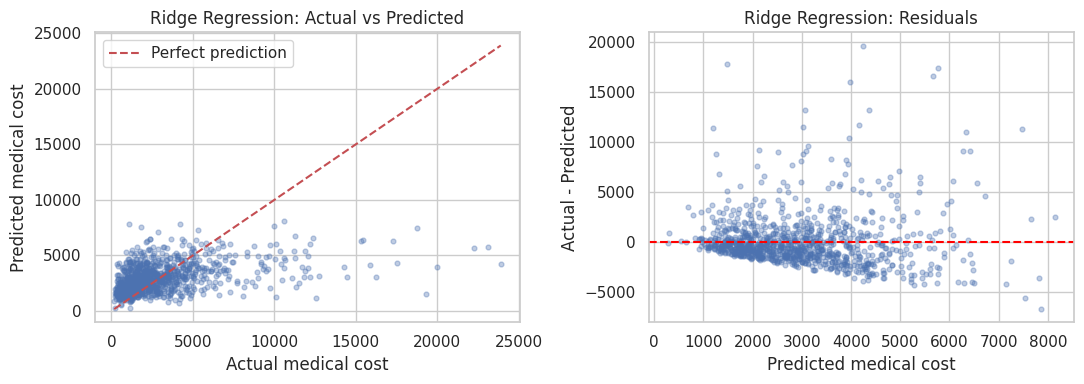

In [10]:
m_2=run_regression('Ridge Regression',Ridge(alpha=10.0))

### 3. Lasso Regression
**Lasso:** L1 regularisation can set some coefficients to zero (feature selection).

Lasso Regression
Train R2: 0.179 | Test R2: 0.2
RMSE: 2667.94 | MAE: 1692.05
Training seconds: 0.1


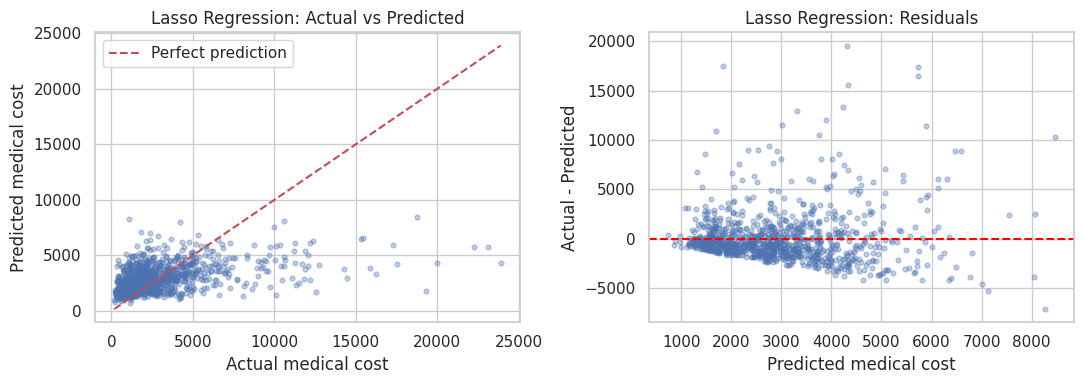

In [11]:
m_3=run_regression('Lasso Regression',Lasso(alpha=20.0,max_iter=5000))

In [12]:
lasso_coefs=m_3.named_steps['model'].coef_
print('Lasso coefficients set to zero:',int(np.isclose(lasso_coefs,0).sum()),'out of',len(lasso_coefs))

Lasso coefficients set to zero: 54 out of 85


### 4. ElasticNet Regression
**ElasticNet:** A blend of Ridge and Lasso (L1 + L2).

ElasticNet Regression
Train R2: 0.184 | Test R2: 0.186
RMSE: 2690.22 | MAE: 1705.03
Training seconds: 0.1


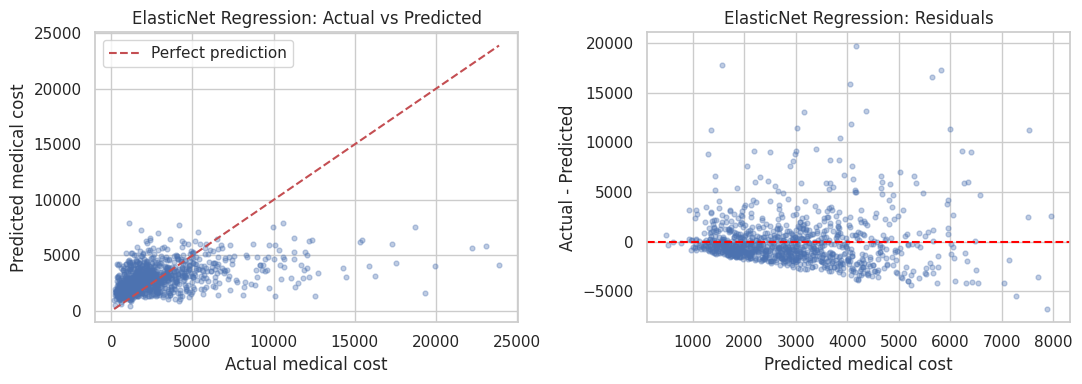

In [13]:
m_4=run_regression('ElasticNet Regression',ElasticNet(alpha=0.1,l1_ratio=0.5,max_iter=4000))

### 5. Polynomial Regression
**Polynomial:** Nonlinear combinations after PCA. This uses the same raw input rows and preprocessing, followed by PCA to keep the polynomial expansion easy to run.

Polynomial Regression
Train R2: 0.174 | Test R2: 0.173
RMSE: 2711.73 | MAE: 1754.03
Training seconds: 0.1


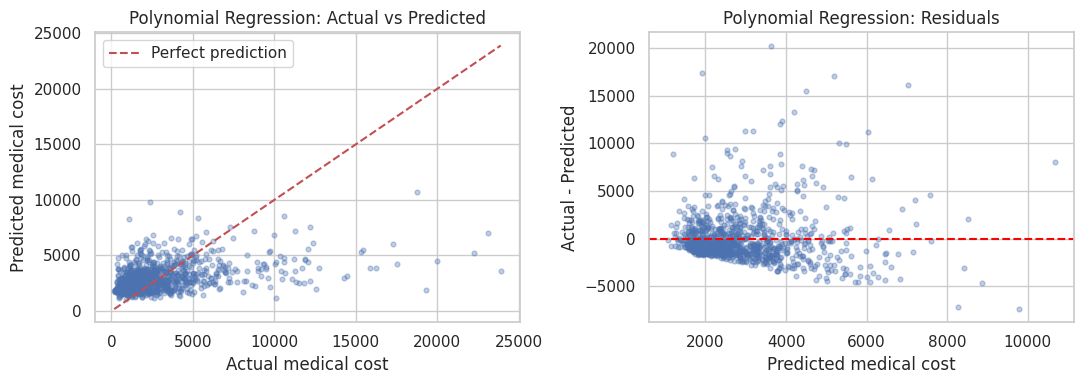

In [14]:
m_5=run_regression('Polynomial Regression',LinearRegression(),extra_step=[('pca',PCA(n_components=7,random_state=SEED)),('polynomial',PolynomialFeatures(degree=2,include_bias=False))])

### 6. Decision Tree Regressor
**Decision Tree:** Recursively makes simple if/else splits to predict cost.

Decision Tree Regressor
Train R2: 0.241 | Test R2: 0.122
RMSE: 2793.96 | MAE: 1770.92
Training seconds: 0.1


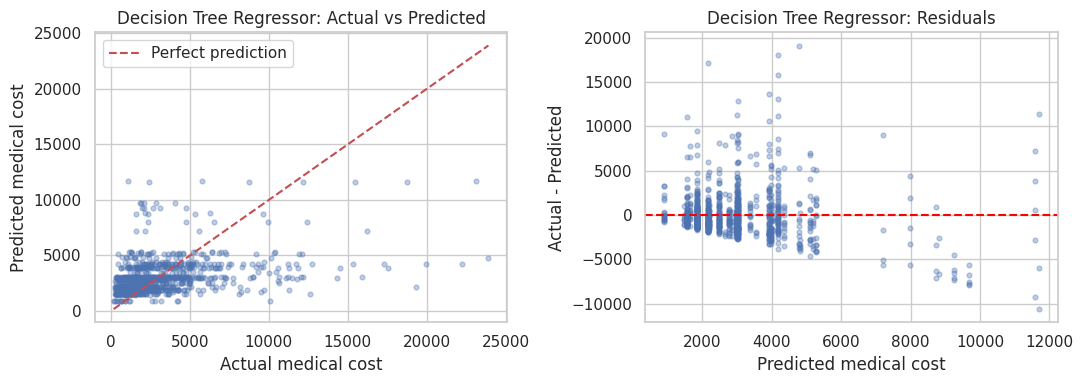

In [15]:
m_6=run_regression('Decision Tree Regressor',DecisionTreeRegressor(max_depth=6,min_samples_leaf=12,random_state=SEED))

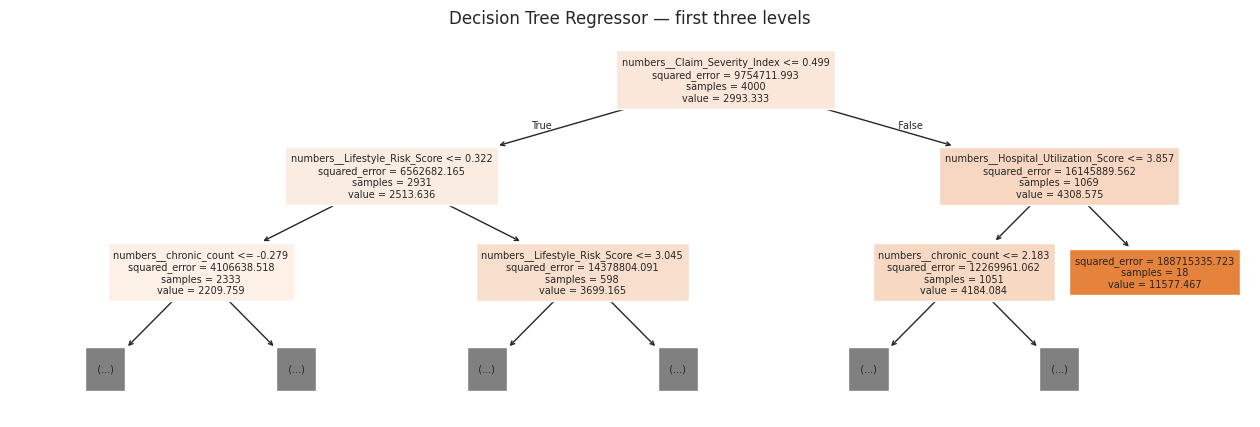

In [16]:
plt.figure(figsize=(16,5))
plot_tree(m_6.named_steps['model'],max_depth=2,feature_names=m_6.named_steps['prepare'].get_feature_names_out(),filled=True,fontsize=7)
plt.title('Decision Tree Regressor — first three levels');plt.show()

### 7. Random Forest Regressor
**Random Forest:** Averages many decision trees; usually more stable than one tree.

Random Forest Regressor
Train R2: 0.601 | Test R2: 0.14
RMSE: 2765.7 | MAE: 1750.51
Training seconds: 1.1


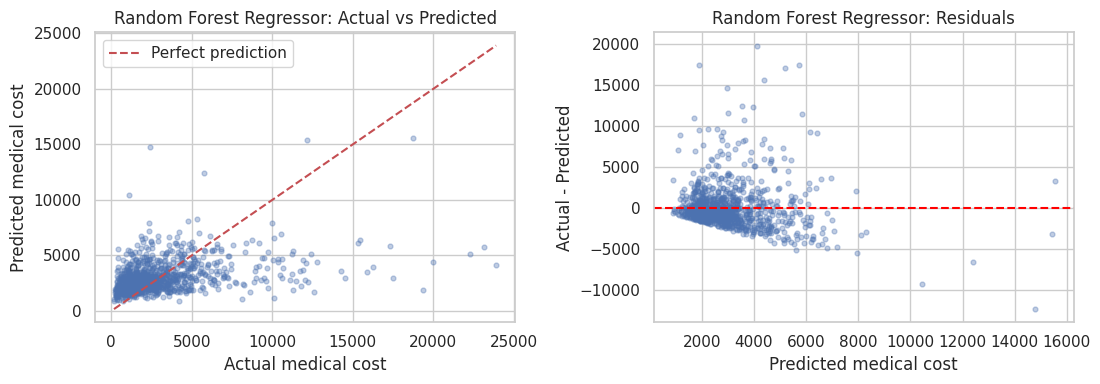

In [17]:
m_7=run_regression('Random Forest Regressor',RandomForestRegressor(n_estimators=60,max_depth=12,min_samples_leaf=3,random_state=SEED,n_jobs=2))

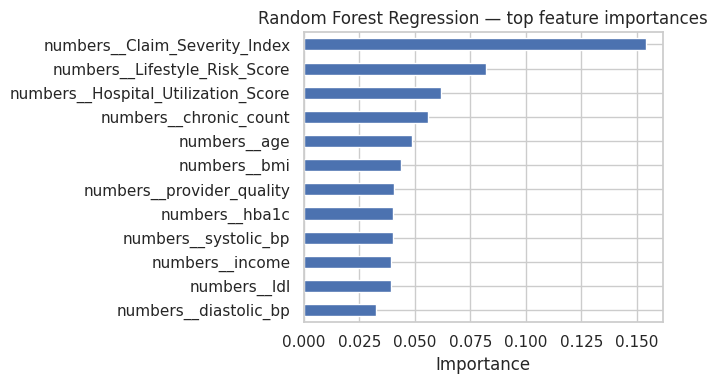

In [18]:
imp=pd.Series(m_7.named_steps['model'].feature_importances_,index=m_7.named_steps['prepare'].get_feature_names_out()).nlargest(12)
imp.sort_values().plot.barh(figsize=(7,4),title='Random Forest Regression — top feature importances');plt.xlabel('Importance');plt.tight_layout();plt.show()

### 8. Gradient Boosting Regressor
**Gradient Boosting:** Trees are added in sequence to correct earlier errors.

Gradient Boosting Regressor
Train R2: 0.418 | Test R2: 0.081
RMSE: 2859.13 | MAE: 1769.34
Training seconds: 1.1


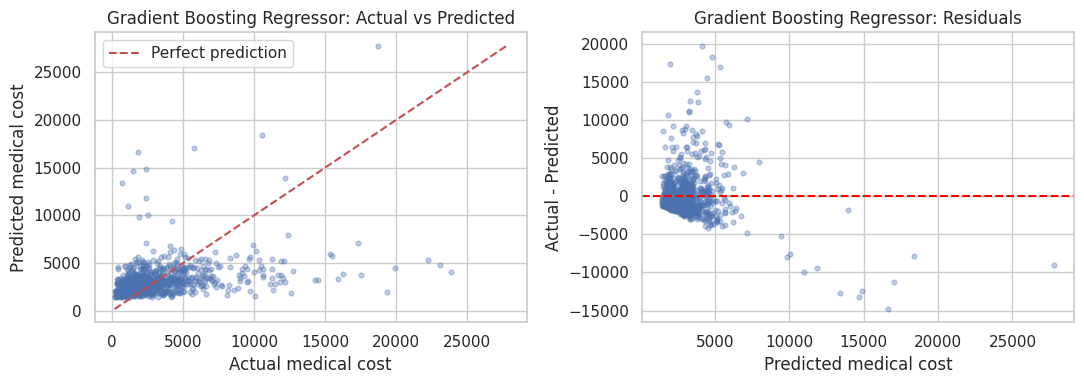

In [19]:
m_8=run_regression('Gradient Boosting Regressor',GradientBoostingRegressor(n_estimators=75,max_depth=3,learning_rate=.07,random_state=SEED))

### 9. Support Vector Regressor
**SVR:** Uses a margin and kernel to learn nonlinear relationships; scaling matters.

Support Vector Regressor
Train R2: 0.212 | Test R2: 0.078
RMSE: 2864.39 | MAE: 1653.43
Training seconds: 1.7


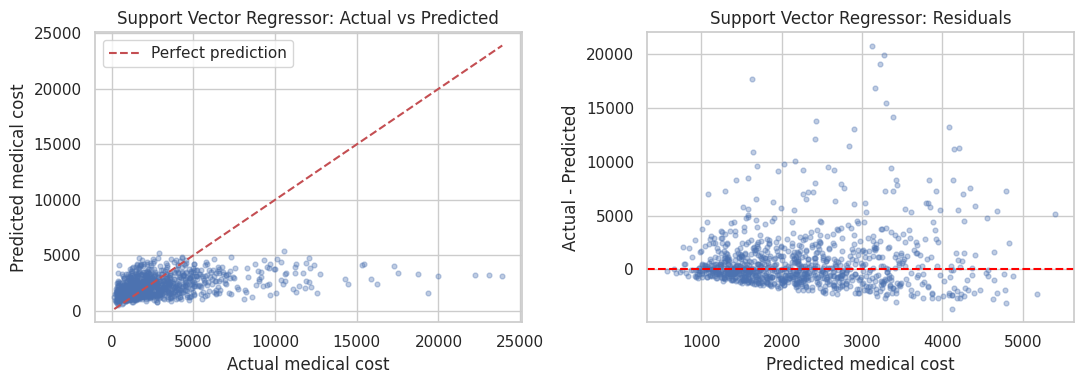

In [20]:
m_9=run_regression('Support Vector Regressor',SVR(C=1000,epsilon=100,kernel="rbf"))

### 10. K-Nearest Neighbors Regressor
**KNN Regressor:** Predicts from the nearest patients; scaling matters because distance is used.

K-Nearest Neighbors Regressor
Train R2: 0.269 | Test R2: 0.065
RMSE: 2883.61 | MAE: 1816.01
Training seconds: 0.1


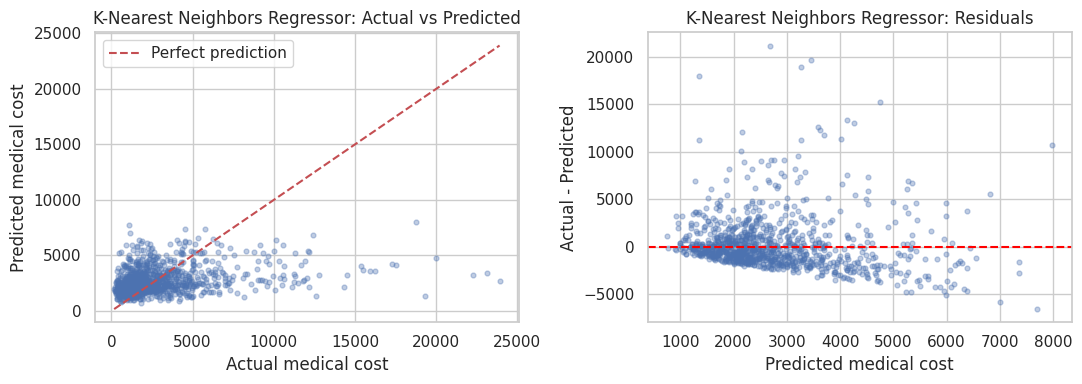

In [21]:
m_10=run_regression('K-Nearest Neighbors Regressor',KNeighborsRegressor(n_neighbors=9,n_jobs=2))

## 4. One clear comparison table + chart  
**Interpretation:** Higher R² is better; lower RMSE and MAE are better. Training R² much higher than testing R² suggests overfitting.

,Model,Train R2,Test R2,RMSE,MAE
0,Lasso Regression,0.179,0.200,"2,668","1,692"
1,ElasticNet Regression,0.184,0.186,"2,690","1,705"
2,Ridge Regression,0.185,0.182,"2,698","1,712"
3,Linear Regression,0.185,0.181,"2,699","1,712"
4,Polynomial Regression,0.174,0.173,"2,712","1,754"
5,Random Forest Regressor,0.601,0.140,"2,766","1,751"
6,Decision Tree Regressor,0.241,0.122,"2,794","1,771"
7,Gradient Boosting Regressor,0.418,0.081,"2,859","1,769"
8,Support Vector Regressor,0.212,0.078,"2,864","1,653"
9,K-Nearest Neighbors Regressor,0.269,0.065,"2,884","1,816"


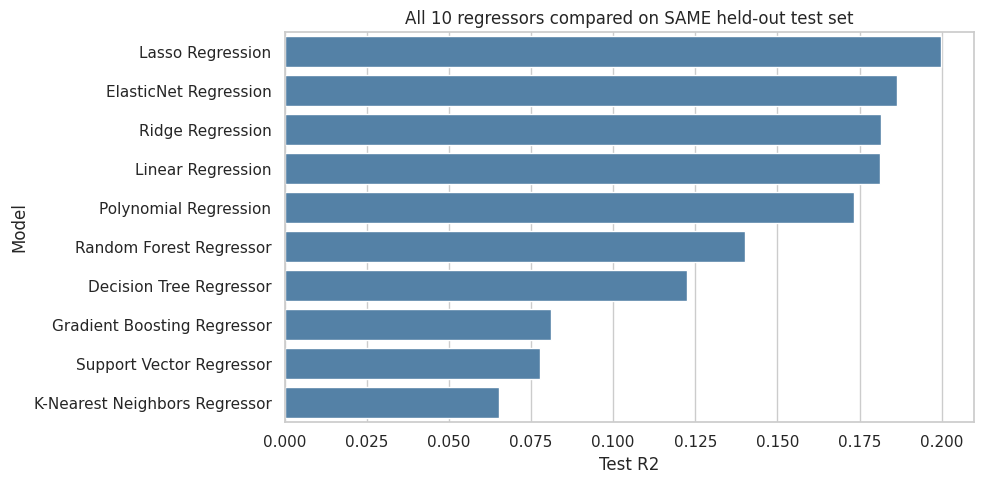

In [22]:
reg_table=pd.DataFrame(reg_results).sort_values('Test R2',ascending=False).reset_index(drop=True)
display(reg_table.style.format({'Train R2':'{:.3f}','Test R2':'{:.3f}','RMSE':'{:,.0f}','MAE':'{:,.0f}'}))
reg_table.to_csv(RESULTS/'regression_comparison.csv',index=False)
plt.figure(figsize=(10,5));sns.barplot(data=reg_table,y='Model',x='Test R2',color='steelblue');plt.title('All 10 regressors compared on SAME held-out test set');plt.tight_layout();plt.show()


## 5. Five-fold cross-validation for two leading models  
To avoid choosing a model based only on the test set, we first select the two leading candidates using a **training-only validation split**, then perform five-fold CV. We report results transparently.

In [23]:
# Internal validation ranking (held-out test set NOT touched)
X_dev,X_val,y_dev,y_val=train_test_split(X_train,y_train,test_size=.2,random_state=SEED)
validation=[]
for name,fitted in reg_models.items():
    candidate=clone(fitted);candidate.fit(X_dev,y_dev)
    validation.append({'Model':name,'Validation R2':r2_score(y_val,candidate.predict(X_val))})
validation_table=pd.DataFrame(validation).sort_values('Validation R2',ascending=False)
display(validation_table)
top_two=validation_table.head(2)['Model'].tolist()
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
cv_table=[]
for name in top_two:
    scores=cross_val_score(clone(reg_models[name]),X_train,y_train,cv=cv,scoring='r2',n_jobs=2)
    cv_table.append({'Model':name,'CV mean R2':scores.mean(),'CV std':scores.std()})
cv_table=pd.DataFrame(cv_table).sort_values('CV mean R2',ascending=False)
display(cv_table)
cv_table.to_csv(RESULTS/'regression_cv.csv',index=False)


,Model,Validation R2
4,Polynomial Regression,0.145839
2,Lasso Regression,0.137728
3,ElasticNet Regression,0.132799
7,Gradient Boosting Regressor,0.130659
1,Ridge Regression,0.127019
0,Linear Regression,0.126190
6,Random Forest Regressor,0.110576
8,Support Vector Regressor,0.076213
9,K-Nearest Neighbors Regressor,0.070092
5,Decision Tree Regressor,-0.003838


,Model,CV mean R2,CV std
1,Lasso Regression,0.159318,0.024232
0,Polynomial Regression,0.124917,0.014057


## 6. Hyperparameter tuning for **two models**  
We tune Ridge and Random Forest on the training portion only, using the same three-fold CV for baseline vs tuned comparisons. A negative or zero improvement is reported honestly.

In [24]:
reg_tune={
 'Ridge Regression':{'model__alpha':[.1,1,10,100]},
 'Random Forest Regressor':{'model__max_depth':[7,12],'model__min_samples_leaf':[2,5]}
}
reg_tuned={};reg_tune_rows=[]
cv3=KFold(n_splits=3,shuffle=True,random_state=SEED)
for name,grid in reg_tune.items():
    baseline=clone(reg_models[name]);base_score=cross_val_score(baseline,X_train,y_train,cv=cv3,scoring='r2',n_jobs=2).mean()
    search=GridSearchCV(clone(reg_models[name]),grid,cv=cv3,scoring='r2',n_jobs=2)
    search.fit(X_train,y_train)
    reg_tuned[name]=search.best_estimator_
    reg_tune_rows.append({'Model':name,'Baseline CV R2':base_score,'Tuned CV R2':search.best_score_,'CV improvement':search.best_score_-base_score,'Best params':str(search.best_params_)})
reg_tune_table=pd.DataFrame(reg_tune_rows);display(reg_tune_table)
reg_tune_table.to_csv(RESULTS/'regression_tuning.csv',index=False)


,Model,Baseline CV R2,Tuned CV R2,CV improvement,Best params
0,Ridge Regression,0.142801,0.149906,0.007105,{'model__alpha': 100}
1,Random Forest Regressor,0.132655,0.148313,0.015658,"{'model__max_depth': 7, 'model__min_samples_le..."


## 7. Save final regression pipeline + discussion  
The winning **baseline** is selected by five-fold CV among two training-validation finalists. We only replace it with a tuned version when comparable CV shows a genuine gain. Do not claim an improvement if the score did not rise.

In [25]:
best_reg_name=cv_table.iloc[0]['Model']
best_reg=reg_models[best_reg_name]
if best_reg_name in reg_tuned:
    row=reg_tune_table.set_index('Model').loc[best_reg_name]
    if row['CV improvement']>0:
        best_reg=reg_tuned[best_reg_name]
joblib.dump(best_reg,MODELS/'best_regressor.joblib')
print('CV-selected model:',best_reg_name)
print('Test RMSE:',np.sqrt(mean_squared_error(y_test,best_reg.predict(X_test))))
print('Saved:',MODELS/'best_regressor.joblib')
print('Classroom question: Why may train and test R² be different?')


CV-selected model: Lasso Regression
Test RMSE: 2667.9409277223763
Saved: models/best_regressor.joblib
Classroom question: Why may train and test R² be different?


### Your team’s analysis (complete yourselves)
- Which scatter plot looks closest to the diagonal? What does the residual plot show?
- Which model overfit? Compare Train R² and Test R².
- Explain the most important features without claiming causation.
- What does the 5-fold CV reveal about stability?
- **Report limitation:** This notebook runs on a fixed sample of the instructor-provided data by default, not all 100,000 rows.